In [1]:
import pandas as pd
from pathlib import Path
import hashlib
from sklearn.model_selection import train_test_split

import time
import json
import os
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import joblib

In [3]:
path = Path.home() / 'ml-lab/data/raw/dataset_1.csv'
df = pd.read_csv(path)

print("Shape:", df.shape)
print("Types:\n", df.dtypes)
print("Nulls:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

print("Distribution:\n", df["label"].value_counts(normalize=True))



Shape: (752842, 45)
Types:
 flow_id                                  object
timestamp                                object
src_ip                                   object
src_port                                  int64
dst_ip                                   object
dst_port                                  int64
duration                                float64
total_bytes                               int64
receiving_bytes                           int64
sending_bytes                             int64
packets_rate                            float64
packets_len_rate                        float64
min_packets_len                           int64
max_packets_len                           int64
mean_packets_len                        float64
standard_deviation_packets_len          float64
variance_packets_len                    float64
coefficient_of_variation_packets_len    float64
dns_domain_name                          object
dns_top_level_domain                     object
dns_second_l

In [18]:
path = Path.home() / 'ml-lab/data/raw/dataset_1.csv'
df = pd.read_csv(path)

df = df.drop_duplicates().dropna()

df['label'] = df['label'].map({'Benign': 0, 'Malicious': 1})

X = df.select_dtypes(include=['number']).drop(columns=['label'], errors='ignore')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:\n", y_train.value_counts(normalize=True))
print("y_test:\n", y_test.value_counts(normalize=True))

X_train.to_csv('../data/X_train_v1.csv', index=False)
X_test.to_csv('../data/X_test_v1.csv', index=False)
y_train.to_csv('../data/y_train_v1.csv', index=False)
y_test.to_csv('../data/y_test_v1.csv', index=False)

X_train: (376421, 31)
X_test: (376421, 31)
y_train:
 label
1    0.500001
0    0.499999
Name: proportion, dtype: float64
y_test:
 label
0    0.500001
1    0.499999
Name: proportion, dtype: float64


/home/mluser/ml-lab/.venv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Train time: 267.30s
Accuracy: 0.9796 | F1 (weighted): 0.9795
Baseline (majority class) Accuracy: 0.5000

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.96      0.98    188211
           1       0.97      0.99      0.98    188210

    accuracy                           0.98    376421
   macro avg       0.98      0.98      0.98    376421
weighted avg       0.98      0.98      0.98    376421


--- False Positives (Benign -> Malicious) ---
     duration  total_bytes  dns_domain_name_length  y_true  y_pred
70    0.16990          446                      20       0       1
104   1.28767          401                      23       0       1
155   0.28344          426                      18       0       1

--- False Negatives (Malicious -> Benign) ---
      duration  total_bytes  dns_domain_name_length  y_true  y_pred
316    0.01578          329                      67       1       0
648    0.00210          345                   

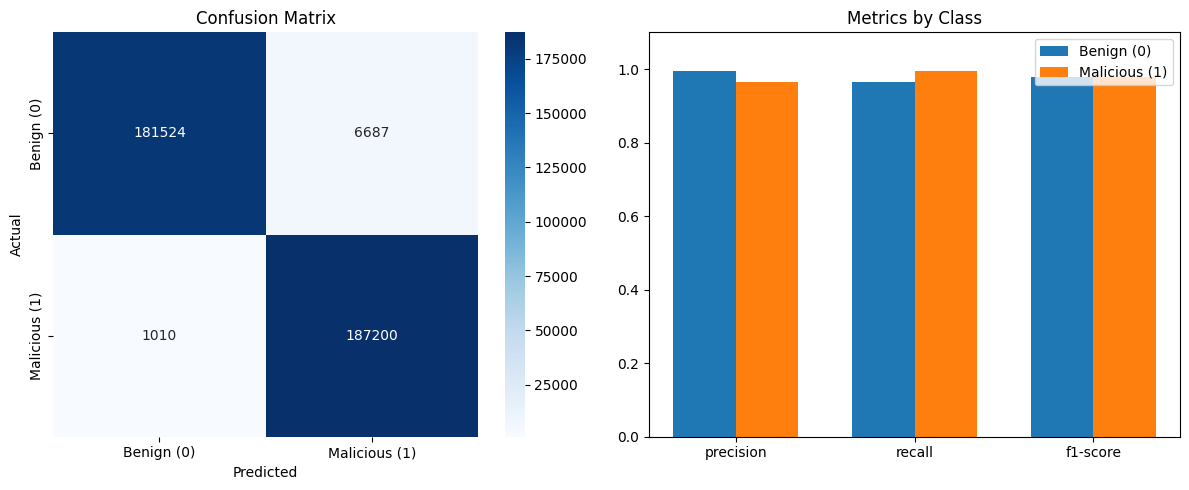


Saved: metrics/baseline.json, models/logistic_regression_model.onnx


In [19]:
X_train = pd.read_csv('../data/X_train_v1.csv')
X_test = pd.read_csv('../data/X_test_v1.csv')
y_train = pd.read_csv('../data/y_train_v1.csv').squeeze()
y_test = pd.read_csv('../data/y_test_v1.csv').squeeze()

def get_sha256(filepath):
    h = hashlib.sha256()
    with open(filepath, "rb") as f:
        for block in iter(lambda: f.read(4096), b""):
            h.update(block)
    return h.hexdigest()

data_sha256 = get_sha256('../data/raw/dataset_1.csv')

start_time = time.time()
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train, y_train)
train_time = time.time() - start_time

y_pred = model.predict(X_test)
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

acc = report_dict['accuracy']
f1_weighted = report_dict['weighted avg']['f1-score']
baseline_acc = max(y_train.value_counts(normalize=True))
print(f"Train time: {train_time:.2f}s")
print(f"Accuracy: {acc:.4f} | F1 (weighted): {f1_weighted:.4f}")
print(f"Baseline (majority class) Accuracy: {baseline_acc:.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

errors = X_test[y_test != y_pred].copy()
errors['y_true'] = y_test[y_test != y_pred]
errors['y_pred'] = y_pred[y_test != y_pred]

print("\n--- False Positives (Benign -> Malicious) ---")
print(errors[errors['y_true'] == 0].head(3)[['duration', 'total_bytes', 'dns_domain_name_length', 'y_true', 'y_pred']].to_string())

print("\n--- False Negatives (Malicious -> Benign) ---")
print(errors[errors['y_true'] == 1].head(3)[['duration', 'total_bytes', 'dns_domain_name_length', 'y_true', 'y_pred']].to_string())

os.makedirs('../metrics', exist_ok=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign (0)', 'Malicious (1)'], yticklabels=['Benign (0)', 'Malicious (1)'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.subplot(1, 2, 2)
metrics_to_plot = ['precision', 'recall', 'f1-score']
class_0 = [report_dict['0'][m] for m in metrics_to_plot]
class_1 = [report_dict['1'][m] for m in metrics_to_plot]
x = range(len(metrics_to_plot))
width = 0.35
plt.bar([i - width/2 for i in x], class_0, width, label='Benign (0)')
plt.bar([i + width/2 for i in x], class_1, width, label='Malicious (1)')
plt.xticks(x, metrics_to_plot)
plt.ylim(0, 1.1)
plt.title('Metrics by Class')
plt.legend()

plt.tight_layout()
plt.show()

metrics = {
    "data_version_sha256": data_sha256,
    "model": "LogisticRegression",
    "parameters": {"max_iter": 1000, "random_state": 42},
    "train_time_seconds": round(train_time, 2),
    "test_size": int(len(y_test)),
    "main_metric": "F1-weighted",
    "main_metric_value": round(f1_weighted, 4),
    "accuracy": round(acc, 4),
    "per_class_metrics": {
        "Benign (0)": {k: round(v, 4) for k, v in report_dict['0'].items() if isinstance(v, (int, float))},
        "Malicious (1)": {k: round(v, 4) for k, v in report_dict['1'].items() if isinstance(v, (int, float))}
    }
}

with open('../metrics/baseline.json', 'w') as f:
    json.dump(metrics, f, indent=2)

os.makedirs('../models', exist_ok=True)
initial_type = [('float_input', FloatTensorType([None, X_train.shape[1]]))]
onnx_model = convert_sklearn(model, initial_types=initial_type)

with open("../models/logistic_regression_model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())


print("\nSaved: metrics/baseline.json, models/logistic_regression_model.onnx")

In [14]:
coeffs = pd.DataFrame({
    'feature': X_train.columns,
    'weight': model.coef_[0]
})
coeffs['abs_weight'] = coeffs['weight'].abs()

print("--- Топ-5 самых влиятельных признаков ---")
print(coeffs.sort_values('abs_weight', ascending=False).head(5))

--- Топ-5 самых влиятельных признаков ---
                      feature    weight  abs_weight
1                    dst_port -0.352837    0.352837
14     dns_domain_name_length  0.230411    0.230411
15  dns_subdomain_name_length -0.195016    0.195016
26             ttl_values_max -0.188936    0.188936
30         distinct_A_records -0.126992    0.126992
